# Part 3: Network SIR Models

## Disease Spread on Contact Networks

---

## Why SIR Is Unrealistic

The classical SIR model assumes **homogeneous mixing**:
> Everyone meets everyone else with equal probability.

But this is clearly unrealistic:
- You don't have equal contact with every person in your city
- Your contacts are **structured**: family, friends, coworkers, neighbors
- Some people have many contacts (hubs), others have few
- Contact patterns form a **network**

### The Question
**How does network structure affect epidemic dynamics?**

To answer this, we need to move from **mean-field** models to **network** models.

In [1]:
# Setup
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from network_sir import (
    NetworkSIR,
    generate_complete_graph,
    generate_random_graph,
    generate_small_world,
    generate_scale_free,
    plot_network_timeseries
)
from sir import simulate_sir

np.random.seed(42)
print("✓ Setup complete")

✓ Setup complete


## 3.1 Graph Representation

We represent the contact structure as a **graph** (network):

### Nodes
Each node represents an **individual**.

### Edges
An edge between two nodes means they **can transmit** the disease to each other.

### Key Insight
Disease spreads **only along edges**, not through the entire population.

## 3.2 Network Types

We'll explore four fundamental network structures. Each captures a different
assumption about **how people are connected**.

### 1. Complete Graph
Every node is connected to every other node. This is the extreme case of
maximum connectivity — and it recovers **homogeneous mixing**, i.e. the
classical SIR limit. It serves as our reference point: if the network
epidemics converge to the complete-graph result, the network structure
doesn't matter.

### 2. Random Graph (Erdős-Rényi)
Edges are added **independently at random** between every pair of nodes with
probability *p*. The resulting degree distribution is **Poisson** with mean
⟨k⟩ = (n−1)p. Nodes are roughly equally connected — there are no hubs. This
is the classic "random mixing" assumption made slightly more realistic by
limiting contacts to a finite number.

### 3. Small-World Network (Watts-Strogatz)
Start with a regular ring lattice (each node connected to its k nearest
neighbours), then **rewire** each edge with probability *p*. This produces a
network with two properties observed in many real social networks:
- **High clustering** — your friends tend to know each other (clique-like
  local structure), which *slows* local spread.
- **Short average path lengths** — despite the local clustering, a few
  long-range rewired edges create "shortcuts" so any two nodes are only a
  small number of hops apart, which *accelerates* global spread.

Real examples: friendship networks, power grids, neural networks.

### 4. Scale-Free Network (Barabási-Albert)
Nodes are added one at a time and each new node connects to *m* existing
nodes with probability proportional to their current degree (**preferential
attachment** — "the rich get richer"). This produces a **power-law** degree
distribution P(k) ∝ k^−γ: most nodes have very few connections, but a small
number of **hubs** have extremely high degree.

Real examples: the internet, citation networks, airline routes,
protein-interaction networks, and — crucially — many human contact networks.
Hubs act as **super-spreaders**: a single high-degree node can seed an
outbreak across a large fraction of the network very quickly.

## Figure 11: Complete Graph

### What it is
A **complete graph** K_n connects every node to every other node.
With n = 100 nodes there are n(n−1)/2 = 4,950 edges.

### Degree distribution
Every node has degree k = n − 1 = 99 — the distribution is a **Dirac delta**
at k = 99. There is no variability at all.

### Connection to SIR
This is the **network implementation of homogeneous mixing**. Since every
susceptible node is a neighbour of every infected node, the force of infection
on any susceptible is proportional to the total number of infected nodes — 
exactly the β·S·I/N term in the ODE. As n → ∞ the network SIR converges
exactly to the mean-field SIR.

### Why study it?
It gives us a **baseline**: the fastest and largest epidemic any network
topology can produce for a given β. All other topologies should produce
smaller or delayed epidemics because they restrict who can infect whom.

Everyone connected to everyone — this should behave like the classic SIR.

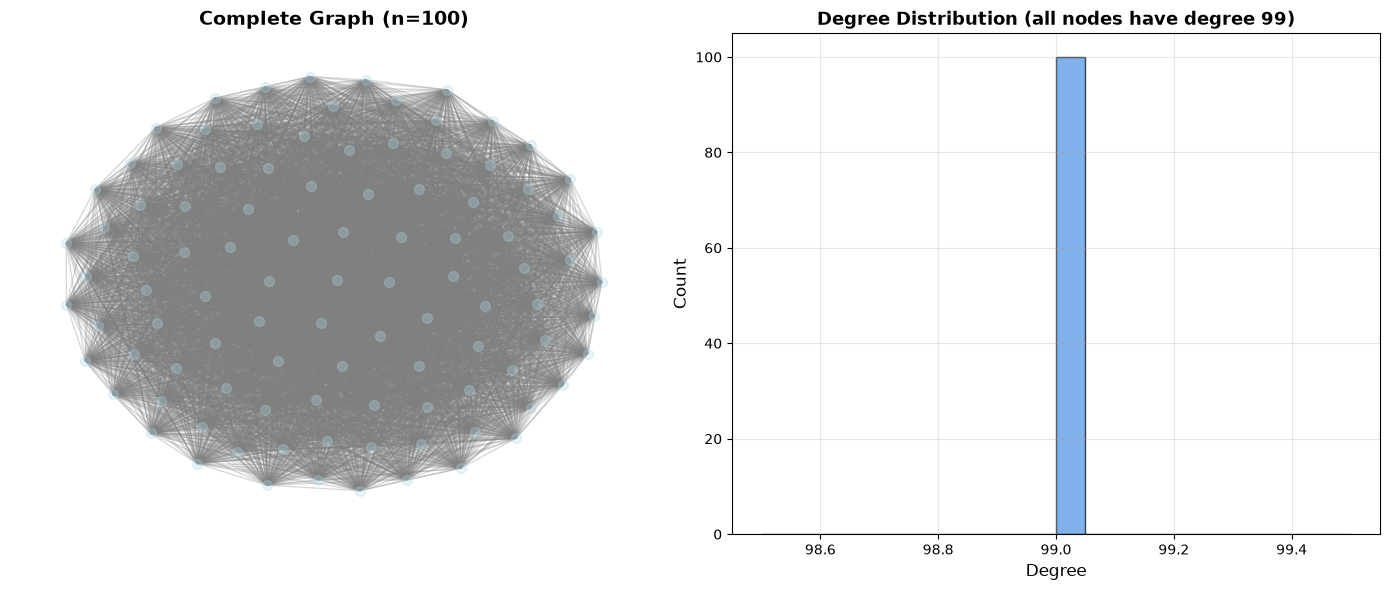

Complete Graph: 100 nodes, 4950 edges
Average degree: 99.0


In [2]:
# Create complete graph
n = 100
G_complete = generate_complete_graph(n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Visualize network
pos = nx.spring_layout(G_complete, seed=42, k=0.5)
nx.draw(G_complete, pos, node_color='lightblue', node_size=50, 
        edge_color='gray', alpha=0.3, ax=ax1, with_labels=False)
ax1.set_title('Complete Graph (n=100)', fontsize=14, fontweight='bold')
ax1.axis('off')

# Network stats
degrees = [d for n, d in G_complete.degree()]
ax2.hist(degrees, bins=20, color='#4A90E2', alpha=0.7, edgecolor='black')
ax2.set_xlabel('Degree', fontsize=12)
ax2.set_ylabel('Count', fontsize=12)
ax2.set_title(f'Degree Distribution (all nodes have degree {n-1})', 
              fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Complete Graph: {G_complete.number_of_nodes()} nodes, {G_complete.number_of_edges()} edges")
print(f"Average degree: {np.mean(degrees):.1f}")

## Figure 12: Random Graph (Erdős-Rényi)

### What it is
The **Erdős-Rényi model** G(n, p) creates a graph on n nodes by including
each of the n(n−1)/2 possible edges **independently** with probability p.

With n = 100 and p = 0.1 we expect ≈ 495 edges and an average degree of
⟨k⟩ = (n−1)·p ≈ 9.9.

### Degree distribution
Each node's degree is the sum of n − 1 independent Bernoulli(p) trials, so
it follows a **Binomial(n−1, p)** distribution. For large n and small p this
is well approximated by a **Poisson** with mean λ = ⟨k⟩:

$$P(k) = \frac{e^{-\lambda}\lambda^k}{k!}$$

The Poisson distribution is **narrow** and **symmetric** around its mean.
There are no hubs: the probability of a node having degree many times larger
than ⟨k⟩ falls off exponentially.

### Key properties
| Property | Value (n=100, p=0.1) |
|---|---|
| Average degree ⟨k⟩ | ≈ 9.9 |
| Variance in degree | ≈ 9.9 (= ⟨k⟩ for Poisson) |
| Clustering coefficient | ≈ p = 0.1 (low) |
| Average path length | O(log n / log ⟨k⟩) (short) |

### Epidemic consequence
Because every node has roughly the same number of contacts, spread is
relatively **uniform**. There are no super-spreaders to kick-start an
outbreak. The epidemic dynamics are close to the mean-field SIR with an
effective β scaled by ⟨k⟩/n, but the stochastic early phase is more
realistic — the epidemic can die out before establishing if the initial seed
is unlucky.

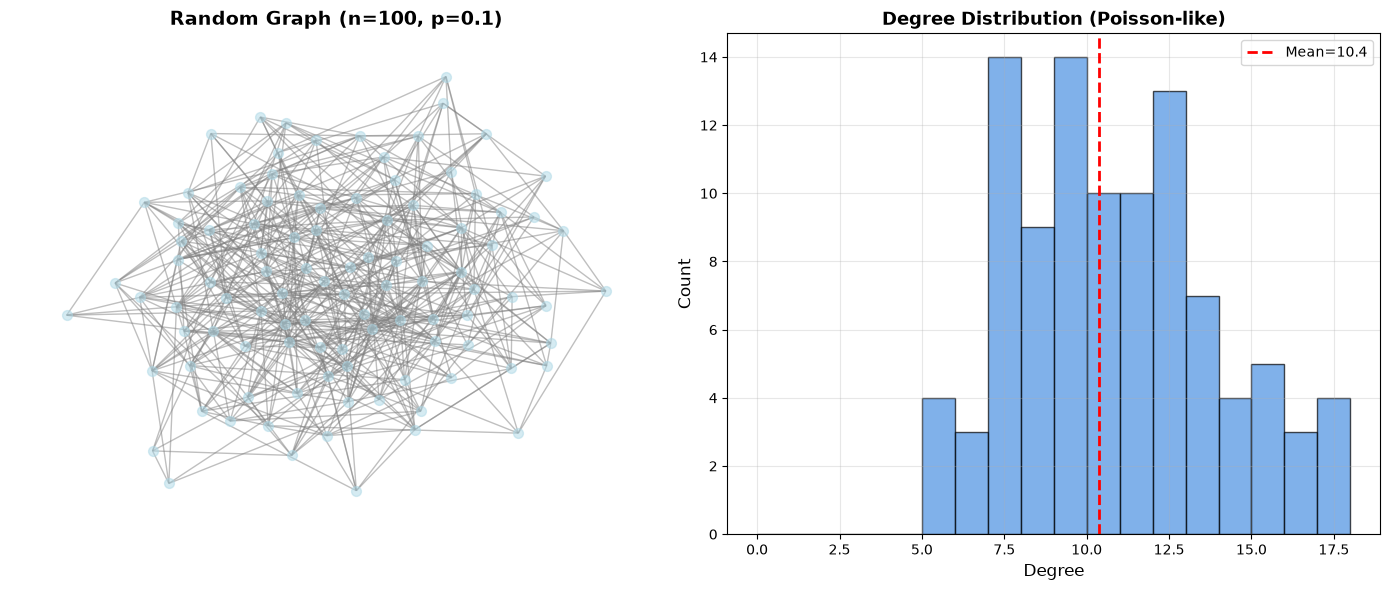

Random Graph: 100 nodes, 519 edges
Average degree: 10.4
Degree range: 5 to 17


In [3]:
# Create random graph
G_random = generate_random_graph(n=100, p=0.1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Visualize
pos = nx.spring_layout(G_random, seed=42)
nx.draw(G_random, pos, node_color='lightblue', node_size=50,
        edge_color='gray', alpha=0.5, ax=ax1, with_labels=False)
ax1.set_title('Random Graph (n=100, p=0.1)', fontsize=14, fontweight='bold')
ax1.axis('off')

# Degree distribution
degrees = [d for n, d in G_random.degree()]
ax2.hist(degrees, bins=range(0, max(degrees)+2), color='#4A90E2', 
         alpha=0.7, edgecolor='black')
ax2.axvline(np.mean(degrees), color='red', linestyle='--', linewidth=2,
           label=f'Mean={np.mean(degrees):.1f}')
ax2.set_xlabel('Degree', fontsize=12)
ax2.set_ylabel('Count', fontsize=12)
ax2.set_title('Degree Distribution (Poisson-like)', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Random Graph: {G_random.number_of_nodes()} nodes, {G_random.number_of_edges()} edges")
print(f"Average degree: {np.mean(degrees):.1f}")
print(f"Degree range: {min(degrees)} to {max(degrees)}")

## Figure 13: Small-World Network (Watts-Strogatz)

### What it is
The **Watts-Strogatz model** WS(n, k, p) is constructed in two steps:

1. **Start with a ring lattice** — place n nodes in a circle, each connected
   to its k nearest neighbours (k/2 on each side). Every node has exactly
   degree k. The graph is highly clustered but has long path lengths.

2. **Rewire** — visit every edge in turn and, with probability p, reconnect
   one endpoint to a uniformly random node (avoiding self-loops and
   duplicates). Small p introduces a handful of long-range "shortcuts".

With n = 100, k = 6, p = 0.3 roughly 30% of edges are rewired.

### The "small-world" phenomenon
Watts and Strogatz (1998) showed that even a tiny fraction of rewired edges
(p ≈ 0.01) dramatically **shrinks average path length** while leaving
**clustering coefficient nearly unchanged**. This captures two features
measured in real social networks:

- *Six degrees of separation* — any two people are connected through ~6 hops.
- *"My friends know each other"* — a high fraction of your neighbours are
  themselves connected.

### Key properties
| Property | Ring lattice (p=0) | Small world (p=0.3) | Random graph |
|---|---|---|---|
| Clustering C | High ≈ 3(k−2)/4(k−1) | Still high | Low ≈ k/n |
| Path length L | Long ≈ n/2k | Short ≈ log n | Short ≈ log n/log k |

### Degree distribution
For small p the distribution remains **narrow** (close to the original
regular k), but develops slight tails from rewiring. It is **not** Poisson
and definitely **not** power-law.

### Epidemic consequence
The tension between clustering and short paths plays out directly in epidemic
dynamics:

- **High clustering** traps infection in local cliques — once a cluster is
  immunised or recovered, the fire wall slows further spread. This **reduces
  the peak and total attack rate** compared with a random graph of the same
  average degree.
- **Short path length** means once the infection crosses a long-range edge it
  can jump to a distant part of the network almost instantly. Epidemics still
  reach most of the network; they just do so **more slowly**.

Small-world networks are a good stylised model for **workplace and school
contact patterns**, where most contacts are within a tight social group but
occasional longer-range contacts (travel, events) link groups together.

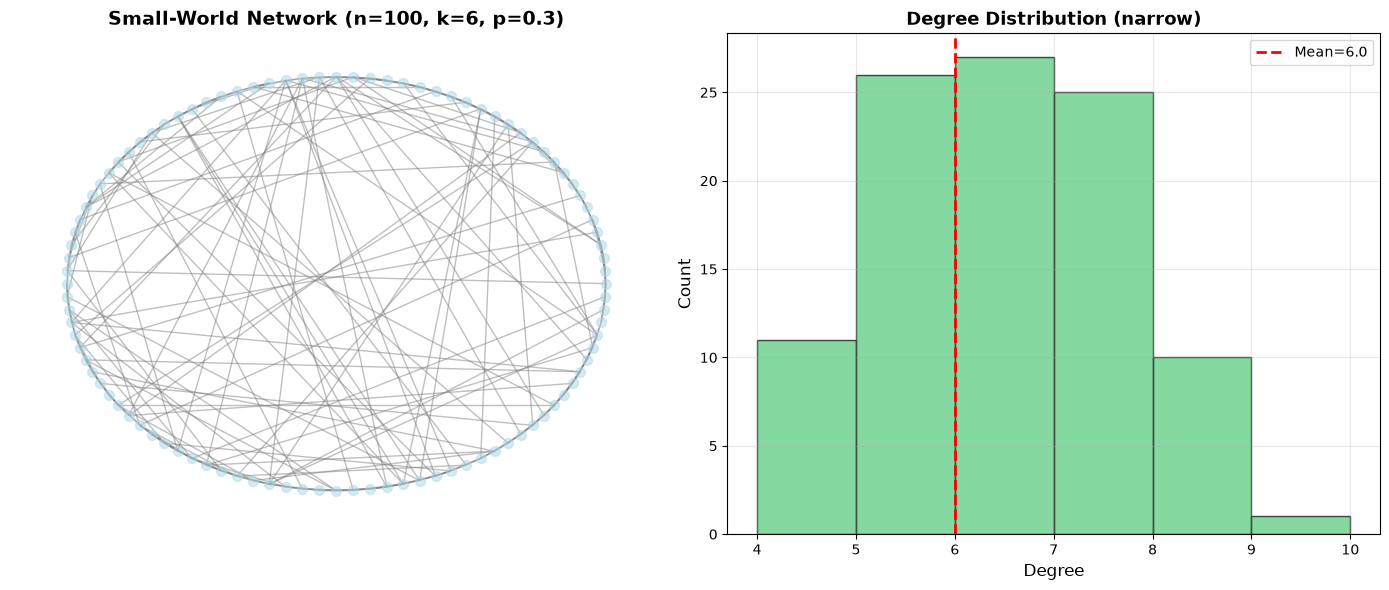

Small-World: 100 nodes, 300 edges
Average degree: 6.0
Clustering coefficient: 0.225
Average path length: 2.97


In [4]:
# Create small-world network
G_sw = generate_small_world(n=100, k=6, p=0.3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Visualize
pos = nx.circular_layout(G_sw)  # Circular layout shows structure better
nx.draw(G_sw, pos, node_color='lightblue', node_size=50,
        edge_color='gray', alpha=0.5, ax=ax1, with_labels=False)
ax1.set_title('Small-World Network (n=100, k=6, p=0.3)', 
              fontsize=14, fontweight='bold')
ax1.axis('off')

# Degree distribution
degrees = [d for n, d in G_sw.degree()]
ax2.hist(degrees, bins=range(min(degrees), max(degrees)+2), color='#50C878',
         alpha=0.7, edgecolor='black')
ax2.axvline(np.mean(degrees), color='red', linestyle='--', linewidth=2,
           label=f'Mean={np.mean(degrees):.1f}')
ax2.set_xlabel('Degree', fontsize=12)
ax2.set_ylabel('Count', fontsize=12)
ax2.set_title('Degree Distribution (narrow)', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Small-World: {G_sw.number_of_nodes()} nodes, {G_sw.number_of_edges()} edges")
print(f"Average degree: {np.mean(degrees):.1f}")
print(f"Clustering coefficient: {nx.average_clustering(G_sw):.3f}")
print(f"Average path length: {nx.average_shortest_path_length(G_sw):.2f}")

## Figure 14: Scale-Free Network (Barabási-Albert)

### What it is
The **Barabási-Albert model** BA(n, m) grows the network by **preferential
attachment**:

1. Start with a small seed graph of m₀ nodes.
2. At each step, add one new node with m edges.
3. Each new edge connects to an existing node i with probability proportional
   to that node's current degree kᵢ:

$$\Pi(i) = \frac{k_i}{\sum_j k_j}$$

This is the "rich get richer" mechanism — nodes that already have many
connections are more likely to attract new ones.

### Degree distribution: Power Law
After many growth steps the degree distribution converges to a **power law**:

$$P(k) \propto k^{-3} \quad (\text{for the BA model})$$

On a log-log plot this is a straight line with slope −3. The key property is
a **heavy tail**: while most nodes have low degree (k ≈ m), there is no
characteristic scale — degrees can range from m to O(√n) for the largest hub.

Compare this to the Poisson (ER) or narrow (WS) distributions: in those
models a node with 10× the mean degree is essentially impossible. In a
scale-free network such hubs are expected and common.

### Key properties
| Property | Scale-Free (BA) |
|---|---|
| Degree distribution | Power law P(k) ∝ k⁻³ |
| Hubs | Yes — a few nodes with very high degree |
| ⟨k²⟩ / ⟨k⟩ | Much larger than ER (diverges as n → ∞) |
| Clustering | Moderate, decreasing with degree |
| Robustness | Robust to random removal, fragile to hub removal |

### Visualisation tip
Node sizes in the plot below are proportional to degree. The large nodes
(hubs) are immediately visible — they are the epidemic drivers.

### Real-world examples
- **Internet router graph** — a few backbone routers carry most traffic.
- **Airline networks** — a few hub airports connect thousands of routes.
- **Social networks** — influencers with millions of followers.
- **Protein interactions** — a few "hub" proteins appear in many pathways.
- **Sexual contact networks** — a key driver of STI transmission.

### Epidemic consequence
Scale-free topology has two critical implications:

1. **No epidemic threshold** — the ratio ⟨k²⟩/⟨k⟩ controls the effective
   R₀ on a network (see Part 4). As n → ∞ this ratio diverges for a
   power-law distribution with exponent ≤ 3, meaning *any* β > 0 can sustain
   an epidemic. There is no safe "low transmission" regime.

2. **Targeted immunisation is highly efficient** — vaccinating the top 5-10%
   highest-degree nodes (hubs) can suppress epidemics far more effectively
   than vaccinating the same fraction randomly. This is the theoretical basis
   for **ring vaccination** and **contact-tracing vaccination** strategies.

This network has **hubs** — a few highly connected nodes that dominate spread.

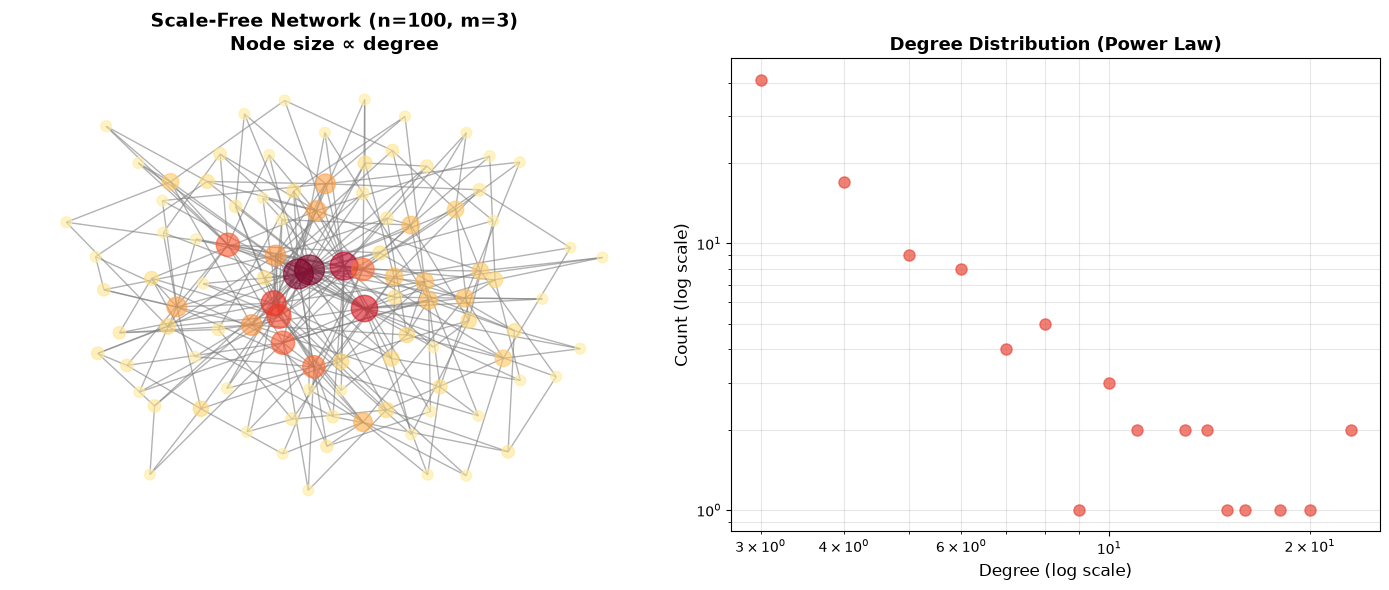

Scale-Free: 100 nodes, 291 edges
Average degree: 5.8
Degree range: 3 to 23
Top 3 hubs: degrees [23, 23, 20]


In [5]:
# Create scale-free network
G_sf = generate_scale_free(n=100, m=3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Visualize with node sizes proportional to degree
degrees = dict(G_sf.degree())
node_sizes = [degrees[node] * 20 for node in G_sf.nodes()]
node_colors = [degrees[node] for node in G_sf.nodes()]

pos = nx.spring_layout(G_sf, seed=42)
nx.draw(G_sf, pos, node_size=node_sizes, node_color=node_colors,
        cmap='YlOrRd', edge_color='gray', alpha=0.6, ax=ax1, 
        with_labels=False, vmin=0, vmax=max(node_colors))
ax1.set_title('Scale-Free Network (n=100, m=3)\nNode size ∝ degree',
              fontsize=14, fontweight='bold')
ax1.axis('off')

# Degree distribution on log-log scale
degree_vals = list(degrees.values())
degree_counts = np.bincount(degree_vals)
degrees_unique = np.arange(len(degree_counts))
mask = degree_counts > 0

ax2.loglog(degrees_unique[mask], degree_counts[mask], 'o', 
           markersize=8, color='#E94B3C', alpha=0.7)
ax2.set_xlabel('Degree (log scale)', fontsize=12)
ax2.set_ylabel('Count (log scale)', fontsize=12)
ax2.set_title('Degree Distribution (Power Law)', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

print(f"Scale-Free: {G_sf.number_of_nodes()} nodes, {G_sf.number_of_edges()} edges")
print(f"Average degree: {np.mean(degree_vals):.1f}")
print(f"Degree range: {min(degree_vals)} to {max(degree_vals)}")
print(f"Top 3 hubs: degrees {sorted(degree_vals, reverse=True)[:3]}")

## 3.3 Epidemics on Networks

### How Network SIR Works

At each time step:
1. **For each infected node**:
   - Try to infect each susceptible **neighbor** with probability β
   - Recover with probability γ
2. **Update all states**

Key difference from classical SIR:
- Infection happens **along edges**, not through mass action
- β is now a **per-contact** transmission probability
- Network structure determines **who can infect whom**

## Comparing Network Types

Let's simulate epidemics on each network type and compare.

In [6]:
# Simulation parameters
beta = 0.3
gamma = 0.1
initial_infected = 5
max_steps = 100

# Networks
networks = {
    'Complete': generate_complete_graph(100),
    'Random': generate_random_graph(100, 0.1),
    'Small World': generate_small_world(100, 6, 0.3),
    'Scale Free': generate_scale_free(100, 3)
}

# Run simulations
results = {}
print("Running network simulations...")
for name, graph in networks.items():
    sim = NetworkSIR(graph, beta=beta, gamma=gamma, initial_infected=initial_infected)
    history = sim.simulate(max_steps=max_steps)
    results[name] = history
    print(f"  ✓ {name}: final R = {history['R'][-1]}")

print("\nSimulations complete!")

Running network simulations...
  ✓ Complete: final R = 100
  ✓ Random: final R = 100
  ✓ Small World: final R = 100
  ✓ Scale Free: final R = 100

Simulations complete!


## Figure 15: Network Epidemic Comparison

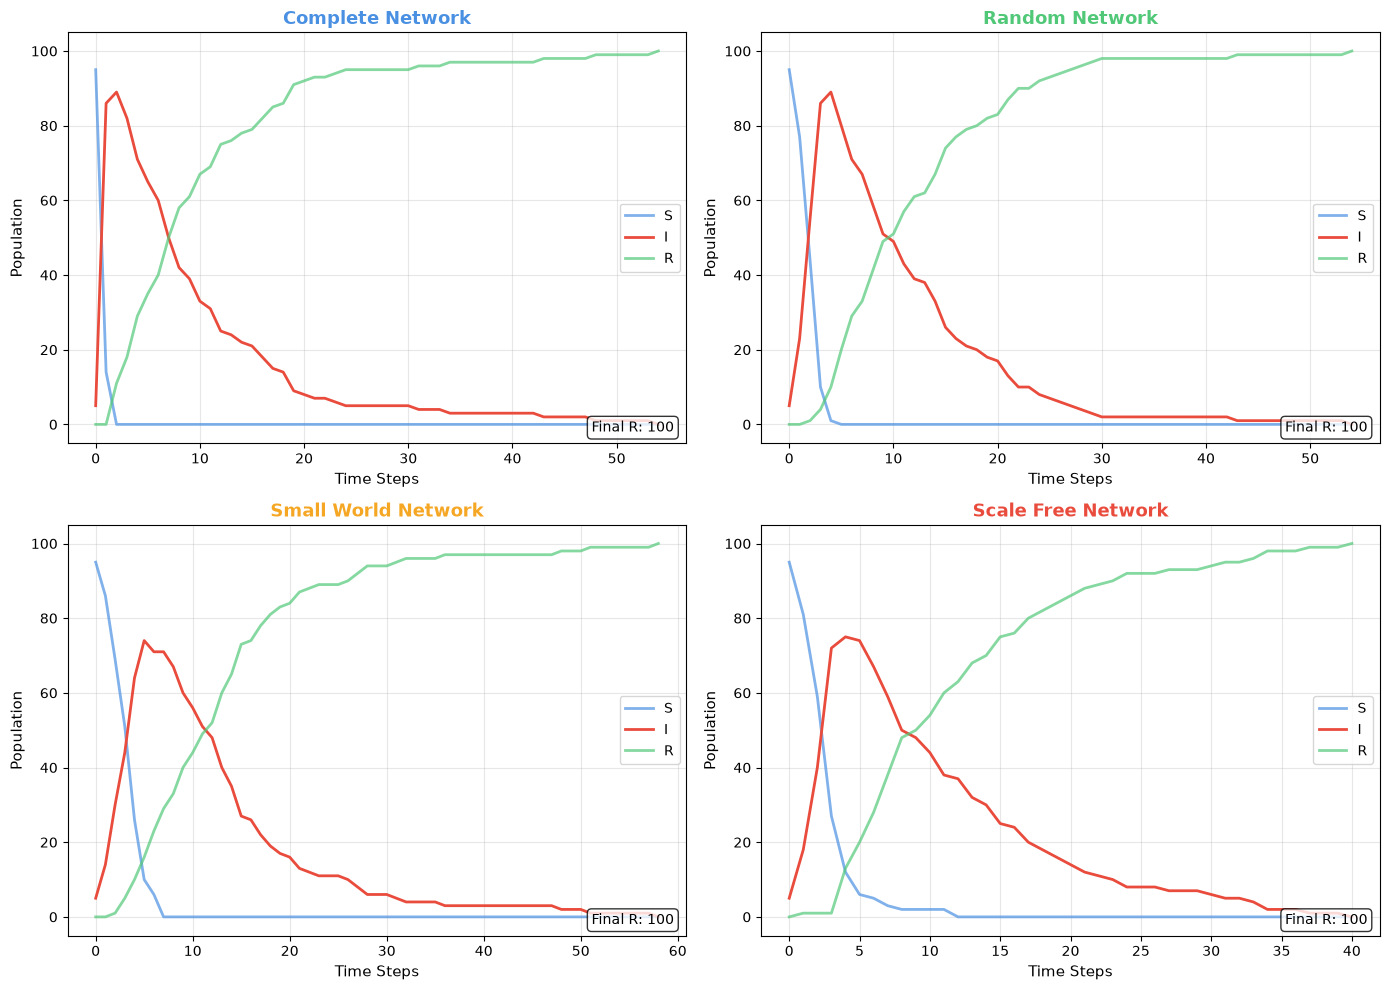


Comparison Summary:
  Complete    : 100 total infected
  Random      : 100 total infected
  Small World : 100 total infected
  Scale Free  : 100 total infected


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

colors = {'Complete': '#4A90E2', 'Random': '#50C878', 
          'Small World': '#F5A623', 'Scale Free': '#E94B3C'}

for idx, (name, history) in enumerate(results.items()):
    ax = axes[idx]
    t = np.arange(len(history['S']))
    
    ax.plot(t, history['S'], label='S', linewidth=2, color='#4A90E2', alpha=0.7)
    ax.plot(t, history['I'], label='I', linewidth=2, color='#E94B3C')
    ax.plot(t, history['R'], label='R', linewidth=2, color='#50C878', alpha=0.7)
    
    ax.set_xlabel('Time Steps', fontsize=11)
    ax.set_ylabel('Population', fontsize=11)
    ax.set_title(f'{name} Network', fontsize=13, fontweight='bold',
                color=colors[name])
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # Add final stats
    final_R = history['R'][-1]
    ax.text(0.98, 0.02, f'Final R: {final_R}', 
           transform=ax.transAxes, ha='right', va='bottom',
           bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
           fontsize=10)

plt.tight_layout()
plt.show()

print("\nComparison Summary:")
for name, history in results.items():
    print(f"  {name:12s}: {history['R'][-1]:3d} total infected")

## Direct Comparison: Infected Over Time

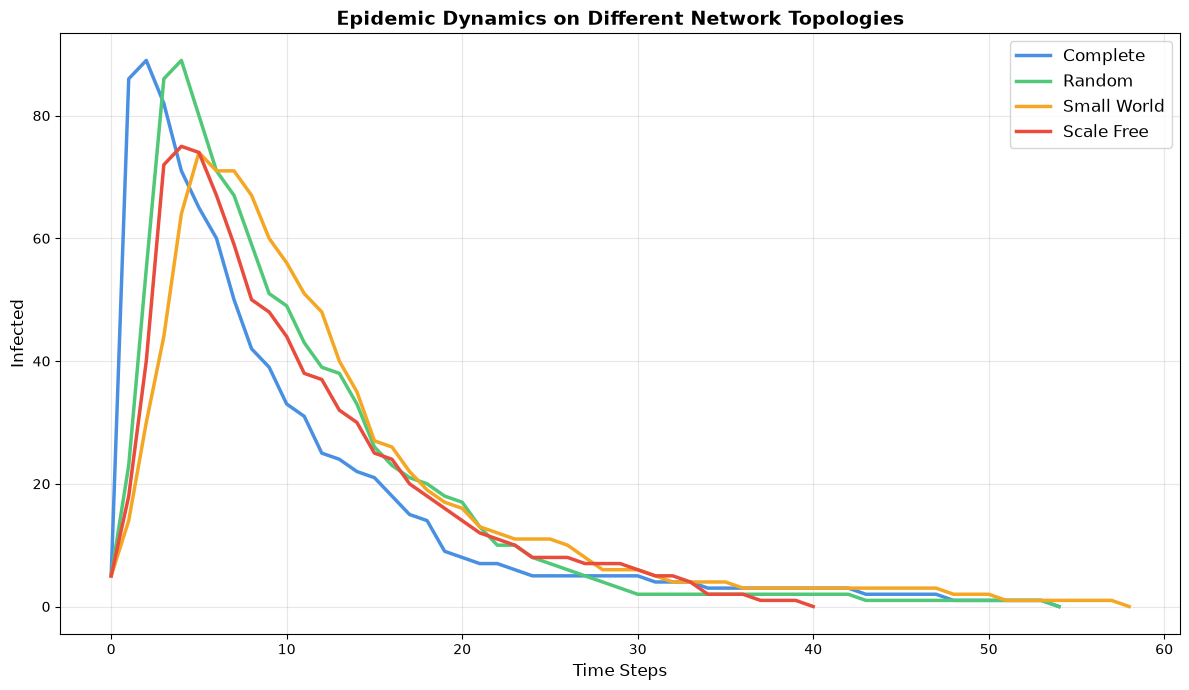

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

for name, history in results.items():
    t = np.arange(len(history['I']))
    ax.plot(t, history['I'], label=name, linewidth=2.5, color=colors[name])

ax.set_xlabel('Time Steps', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Epidemic Dynamics on Different Network Topologies', 
            fontsize=14, fontweight='bold')
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Key Observations

### 1. Complete Graph
- **Fastest spread**, **highest peak**
- Everyone can infect everyone → approaches classical SIR
- No network structure to slow down transmission

### 2. Random Graph
- **Moderate spread**
- Poisson degree distribution → relatively homogeneous
- Some randomness in dynamics

### 3. Small-World Network
- **High clustering** slows local spread
- **Short paths** still allow eventual spread
- Balances local and global connectivity

### 4. Scale-Free Network
- **Hubs accelerate spread**
- Can have **very fast initial growth**
- High-degree nodes act as **super-spreaders**
- Most vulnerable to epidemic outbreaks

## Comparing Network Model with Classical SIR

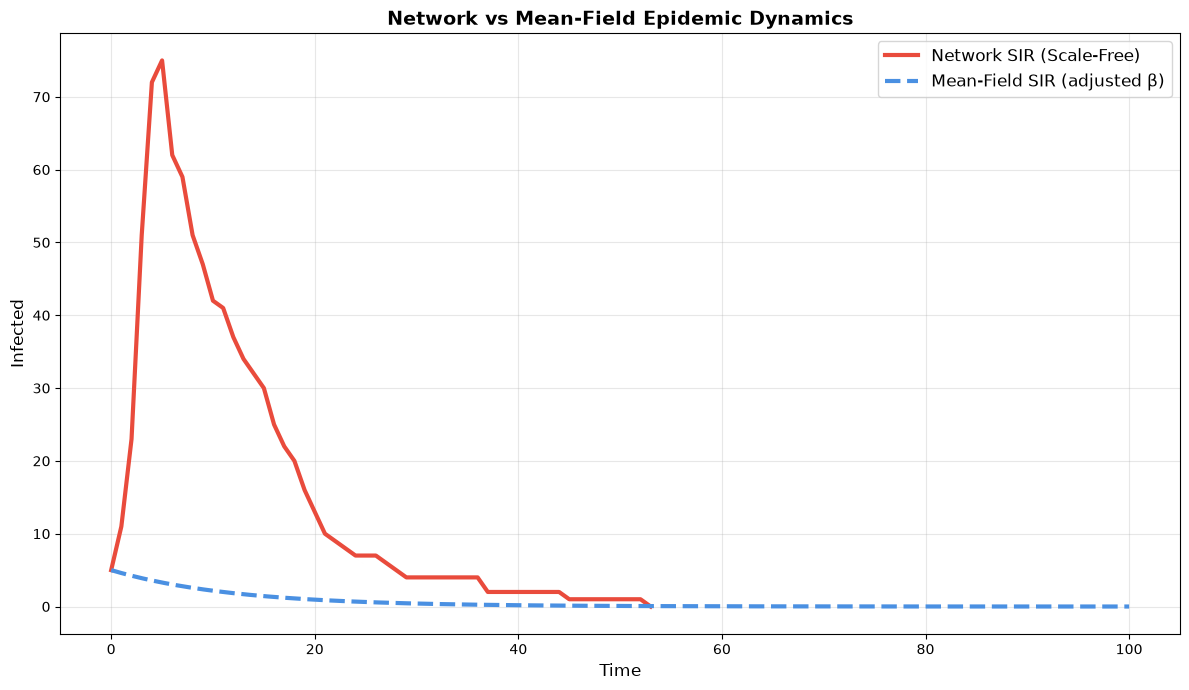

Average degree: 5.8
Network model shows more stochastic behavior and faster initial spread due to hubs


In [9]:
# Compare scale-free network with mean-field SIR
# Adjust beta for mean-field to account for average degree
G = generate_scale_free(100, 3)
avg_degree = np.mean([d for n, d in G.degree()])

# Network simulation
sim = NetworkSIR(G, beta=0.3, gamma=0.1, initial_infected=5)
net_history = sim.simulate(max_steps=100)

# Mean-field SIR with adjusted transmission
beta_mf = 0.3 * avg_degree / 100  # Scale by average contacts
sir_sol = simulate_sir(beta=beta_mf, gamma=0.1, S0=95, I0=5, R0=0, t_span=(0, 100))

# Plot comparison
fig, ax = plt.subplots(figsize=(12, 7))

t_net = np.arange(len(net_history['I']))
ax.plot(t_net, net_history['I'], label='Network SIR (Scale-Free)', 
       linewidth=3, color='#E94B3C')
ax.plot(sir_sol.t, sir_sol.y[1], label='Mean-Field SIR (adjusted β)', 
       linewidth=3, color='#4A90E2', linestyle='--')

ax.set_xlabel('Time', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Network vs Mean-Field Epidemic Dynamics', 
            fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Average degree: {avg_degree:.1f}")
print(f"Network model shows more stochastic behavior and faster initial spread due to hubs")

## Summary

### What We Learned

1. **Network structure matters**
   - Disease spreads along edges, not uniformly
   - Different topologies → different dynamics

2. **Hubs are critical**
   - Scale-free networks have super-spreaders
   - High-degree nodes accelerate epidemics

3. **Clustering affects spread**
   - High clustering slows transmission
   - But short paths allow eventual spread

4. **Complete graph ≈ Classical SIR**
   - When everyone connects to everyone, network models converge to mean-field

### Implications for Control

- **Target hubs** for vaccination (scale-free networks)
- **Network structure** enables targeted interventions
- **Contact tracing** leverages network information

---

## Still Missing

Network models explicitly represent edges, but they still treat all nodes of the same degree as equivalent.

**Next**: We'll develop **degree-based models** that capture heterogeneity analytically.